<a href="https://colab.research.google.com/github/kumaarsharma9-max/Machine-Learning-Beginner-Projects/blob/machine-Learning/Student_Performance_(Multiple_Linear_Regression).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Student Performance (Multiple Linear Regression)**

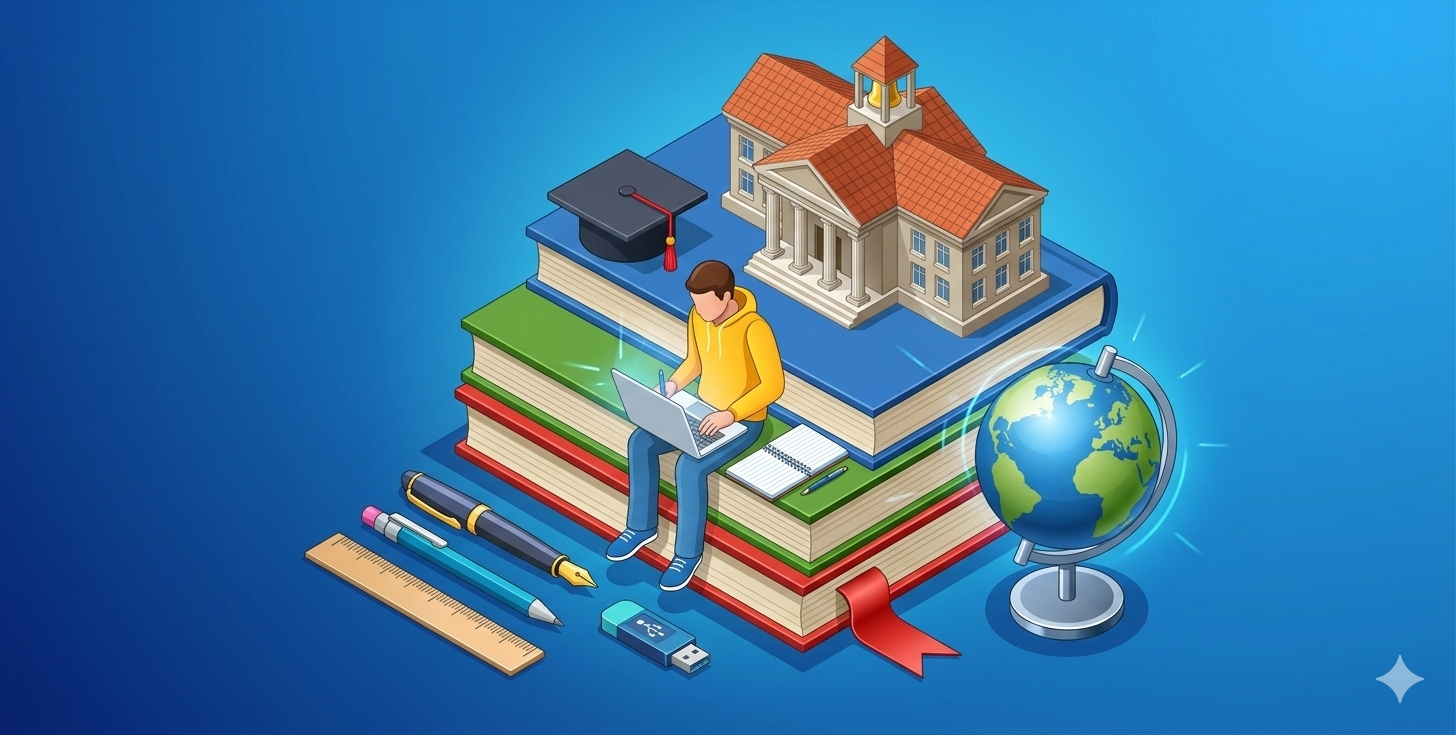

### **About Dataset**

### **Description:**

**The Student Performance Dataset is a dataset designed to examine the factors influencing academic student performance. The dataset consists of 10,000 student records, with each record containing information about various predictors and a performance index.**


### **Variables:**

Hours Studied: The total number of hours spent studying by each student.

Previous Scores: The scores obtained by students in previous tests.

Extracurricular Activities: Whether the student participates in extracurricular activities (Yes or No).

Sleep Hours: The average number of hours of sleep the student had per day.

Sample Question Papers Practiced: The number of sample question papers the student practiced.

Target Variable:
Performance Index: A measure of the overall performance of each student. The performance index represents the student's academic performance and has been rounded to the nearest integer. The index ranges from 10 to 100, with higher values indicating better performance.

The dataset aims to provide insights into the relationship between the predictor variables and the performance index. Researchers and data analysts can use this dataset to explore the impact of studying hours, previous scores, extracurricular activities, sleep hours, and sample question papers on student performance.



### **Import The Nesecessary Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
df = pd.read_csv('/content/Student_Performance.csv')
df.head()

In [ ]:
# total columns and rows in df.shape
df.shape

### **Data Cleaning**

In [ ]:
df.info()

datatypes are correct, and columns names are consistent!

so data is almost cleaned!

In [ ]:
df.isna().sum()

mean -> numerical

median -> numerical

mode() -> categorical

### **Seperate inputs and target variable**

In [ ]:
# inputs for models -> X
X = df.drop(columns=['Performance Index'])

# target variable -> y
y = df[['Performance Index']]

### **Split data into training and testing data**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.25)


In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

### **Feature Engineering**

extract, create, bins -> the features -> to generate some new useful information

This new information actually helps the Model to learn hidden, complex, and useful data patterns!

In [ ]:
X_train['study_efficiency'] = X_train['Hours Studied']/X_train['Sleep Hours']
X_test['study_efficiency'] = X_test['Hours Studied']/X_test['Sleep Hours']

In [ ]:
X_train['prev_scr_hrs'] = X_train['Previous Scores'] * X_train['Hours Studied']

X_test['prev_scr_hrs'] = X_test['Previous Scores'] * X_test['Hours Studied']


In [ ]:
X_train['prev_score_category'] = pd.cut(
    x=X_train['Previous Scores'],
    bins=[0, 40, 60, 80, 100],
    labels=['low_scorer', 'average_scorer', 'good_scorer', 'excellent_scorer']
)

X_test['prev_score_category'] = pd.cut(
    x=X_test['Previous Scores'],
    bins=[0, 40, 60, 80, 100],
    labels=['low_scorer', 'average_scorer', 'good_scorer', 'excellent_scorer']
)


In [ ]:
# extracting the numerical and categorical columns

numerical_cols = X_train.select_dtypes(include="number").columns.tolist()
print(numerical_cols)

categorical_cols = X_train.select_dtypes(include=['category', 'object']).columns.tolist()
print(categorical_cols)

### **Data Preprocessings**

The preprocessing steps applied to data before passing it to the model.

This makes the data consistent, eliminates noise/inconsistencies, and transforms features into a format suitable for machine learning algorithms.

Feature Transformations (log, power) are applied to numerical features, but not all columns.
Checks before applying:

Skewed distribution (high skewness) Presence of extreme values Only positive values (for log)

In [ ]:
X_train.skew(numeric_only=True)

None of these need transformation.

Reason (rule of thumb):

1.  |skew| < 0.5 → good
2.  0.5 – 1 → moderate
3.  '>' 1 → highly skewed

Log transformation compresses large values, reduces skewness, and makes the distribution more balanced for ML models.



**Feature Encodings:**<br>

Convert categorical features into numerical values so that machine learning models can process them.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder( )

ohe

In [ ]:
categorical_cols

In [ ]:
X_train_enc = ohe.fit_transform(X_train[categorical_cols])
X_test_enc = ohe.transform(X_test[categorical_cols])

In [ ]:
X_train_enc = X_train_enc.toarray()
X_test_enc = X_test_enc.toarray()

X_train_enc[2]

**Feature Scaling**<br>

**Change the scale of features and bring them into a consistent range using a specific method.**<br>

**This prevents the model from giving undue importance to features that have larger numerical values but may not actually be more important.**

In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

sc


In [ ]:
numerical_cols


In [ ]:
X_train_sc = sc.fit_transform(X_train[numerical_cols])
X_test_sc = sc.transform(X_test[numerical_cols])

In [ ]:
X_train_sc[2]

finally, merging the encoded and scaled features

In [ ]:
X_train_final = np.hstack((X_train_sc, X_train_enc ))
X_test_final = np.hstack( (X_test_sc, X_test_enc) )
X_train_final[2]


In [ ]:
X_train_final.shape

In [ ]:
# allocate col. names to merged data!
num_cols = numerical_cols
ohe_cols = ohe.get_feature_names_out(categorical_cols)

all_cols = list(num_cols) + list(ohe_cols)

X_train_final = pd.DataFrame(X_train_final, columns=all_cols)
X_test_final = pd.DataFrame(X_test_final, columns=all_cols)


In [ ]:
X_train_final.head(2)

Feature Selection
using correlation ---> will check the correlation between inpust and target, and between inputs as well!

this helps to remove redundant features as well!



In [ ]:
pd.concat([pd.DataFrame(X_train_final), y_train.reset_index(drop=True)], axis=1).corr()


Weak / almost useless:

Feature 2, 3, 6, 10 → near 0

Also notice:

Feature 6 & 7 → -1.0 correlation → perfectly redundant → drop one.

### **Model Building**


**1. Multi Linear Regression**

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr


In [ ]:
lr.fit(X_train_final, y_train)

In [ ]:
y_pred = lr.predict(X_test_final)

In [ ]:
y_pred.dtype

In [ ]:
y_test.dtypes

In [ ]:
type(y_test)

In [ ]:
type(y_pred)

In [ ]:
pd.DataFrame(y_pred)

In [ ]:
combined_result = pd.DataFrame({
    "original": y_test.values.ravel(),
    "predicted": y_pred.ravel()
})

combined_result.head()

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_pred, y_test)
mae = mean_absolute_error(y_pred, y_test)
r2_sc = r2_score(y_pred, y_test)

In [ ]:
print("MSE: ", mse)
print("MAE: ", mae)
print("R2 Score is: ", r2_sc)

rmse = np.sqrt(mse)

print("RMSE: ", rmse)

In [ ]:
import matplotlib.pyplot as plt
residuals = y_test.values.ravel() - y_pred.ravel()
plt.scatter(y_pred, residuals)
plt.axhline(0)

In [ ]:
plt.hist(residuals)

**2 . Polynomial Regression**

In [ ]:
# creating the polynomial features
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
poly

In [ ]:
X_train_final_poly = poly.fit_transform(X_train_final)
X_test_final_poly = poly.transform(X_test_final)

In [ ]:
# building the model instance
poly_model = LinearRegression()
poly_model

In [ ]:
# X_train_final_poly_df = pd.DataFrame()

In [ ]:
# training of model
poly_model.fit(X_train_final_poly, y_train)

In [ ]:
# making the prediction from polynomial model

y_pred_poly = poly_model.predict(X_test_final_poly)

In [ ]:
# checking the metrics of poly. model
mse = mean_squared_error(y_pred_poly, y_test)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_pred_poly, y_test)
r2_sc = r2_score(y_pred_poly, y_test)

In [ ]:
print("MSE: ", mse)
print("RMSE: ", rmse)
print("MAE: ", mae)
print("R2 score: ", r2_sc)

In [ ]:
y_train_pred = poly_model.predict(X_train_final_poly)

train_poly_r2 = r2_score(y_train, y_train_pred)
train_poly_mse = mean_squared_error(y_train, y_train_pred)
train_poly_rmse = np.sqrt(train_poly_mse)
train_poly_mae = mean_absolute_error(y_train, y_train_pred)

In [ ]:
print(train_poly_r2)
print(train_poly_mse)
print(train_poly_rmse)
print(train_poly_mae)

in polynomial regr, the metrics of training and testing data is almost same! which says that the model does not overfits!

**3. Lasso Regularization**

In [ ]:
# building the model instance
from sklearn.linear_model import Lasso

# alpha shows the strength of coeff. (or weights) to consider
la = Lasso(alpha=0.1)

la

In [ ]:
# training the lasso model

la.fit(X_train_final, y_train)

In [ ]:
y_pred_la = la.predict(X_test_final)

In [ ]:
mse = mean_squared_error(y_pred_la, y_test)
mae = mean_absolute_error(y_pred_la, y_test)
rmse = np.sqrt(mse)
r2_sc = r2_score(y_pred_la, y_test)

print("MSE: ", mse)
print("RMSE: ", rmse)
print("MAE: ", mae)
print("R2 score: ", r2_sc)

**4. Ridge Regularization**

In [ ]:
from sklearn.linear_model import Ridge

rdge = Ridge(alpha=100)

rdge

In [ ]:
rdge.fit(X_train_final, y_train)

In [ ]:
y_pred_rdge = rdge.predict(X_test_final)

In [ ]:
mse = mean_squared_error(y_pred_rdge, y_test)
mae = mean_absolute_error(y_pred_rdge, y_test)
rmse = np.sqrt(mse)
r2_sc = r2_score(y_pred_rdge, y_test)

print("MSE: ", mse)
print("RMSE: ", rmse)
print("MAE: ", mae)
print("R2 score: ", r2_sc)


**5 . Cross Validation**

In [ ]:
from sklearn.model_selection import cross_val_score

ln = LinearRegression()

ln

In [ ]:
X_final = pd.concat([X_train_final, X_test_final])
y_final = pd.concat([y_train, y_test])

In [ ]:
cv_score = cross_val_score(ln, X_final, y_final, cv = 5, scoring="r2")

In [ ]:
cv_score

In [ ]:
cv_score.mean()